# Part 1 — Adiabatic Flame Temperature

H$_2$/air, `h2o2.yaml`, equilibrium at constant enthalpy and pressure (HP).

Functions live in `src/ct_utils/general` (calculations) and `src/ct_utils/plots` (plotting). Tables are saved to `results/part1/raw/`, figures to `results/part1/figures/{pdf,jpeg}/`.

## Setup

`ct_utils.set_part("part1")` sends all outputs to `results/part1/`. `plots.set_style()` applies LaTeX fonts and a colourblind-safe palette (Okabe–Ito colours with distinct markers, `viridis` maps).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import cantera as ct
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ct_utils
from ct_utils import general as eq
from ct_utils import plots

ct_utils.set_part("part1")      # outputs go to results/part1/
plots.set_style()
%matplotlib inline

ATM = ct.one_atm      # Pa

# Task 1 — Equivalence Ratio Sweep

$T_\mathrm{ad}$ for $\phi \in [0.4, 3.0]$ at $T_u = 300$ K, 1 atm.

**`eq.equilibrium_temperature(phi, fuel, T_u, p, mechanism, oxidizer)`** returns $T_\mathrm{ad}$ (K) for one condition: set $\phi$, set $(T_u, p)$, `equilibrate("HP")`. Defaults: H$_2$, 300 K, 1 atm, `h2o2.yaml`, air.

Reference value: $\approx 2382$ K.

In [2]:
T_ad_st = eq.equilibrium_temperature(1.0)
print(f"T_ad(phi = 1, T_u = 300 K, 1 atm) = {T_ad_st:.1f} K")

T_ad(phi = 1, T_u = 300 K, 1 atm) = 2387.6 K


$2387.6$ K, within $0.2\,\%$ of the reference.

**`eq.equilibrium_states(phi, T_u, p, ...)`** equilibrates many conditions at once (inputs are broadcast) and returns a `SolutionArray`. `eq.equilibrium_sweep(phi_range, ...)` is the same but returns only $T_\mathrm{ad}$.

**`eq.save_states(states, name)`** saves states to `results/part1/raw/<name>.csv` via `to_pandas()`; **`plots.save_figure(fig, name)`** saves PDF and JPEG.

**`plots.plot(x, y, xlabel, ylabel, figsize, legend=True, grid=True, labels=..., ax=..., vlines=..., hlines=...)`** draws one or several curves.

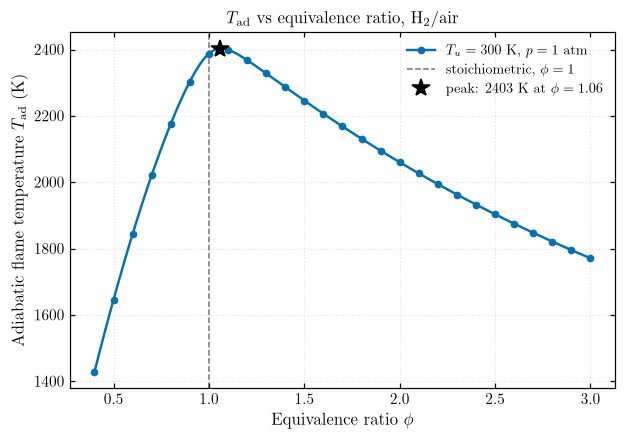

In [3]:
phi = np.linspace(0.4, 3.0, 261)
states_phi = eq.equilibrium_states(phi, T_u=300.0, p=ATM)
eq.save_states(states_phi, "task1_phi_sweep")

T_ad = states_phi.T
k_max = np.argmax(T_ad)

fig, ax = plots.plot(
    phi, T_ad, r"Equivalence ratio $\phi$", r"Adiabatic flame temperature $T_\mathrm{ad}$ (K)",
    labels=[r"$T_u = 300$ K, $p = 1$ atm"], markevery=10,
    vlines={1.0: r"stoichiometric, $\phi = 1$"},
    title=r"$T_\mathrm{ad}$ vs equivalence ratio, H$_2$/air",
)
ax.plot(phi[k_max], T_ad[k_max], "*", color="k", ms=12,
        label=rf"peak: {T_ad[k_max]:.0f} K at $\phi = {phi[k_max]:.2f}$")
ax.legend()
plots.save_figure(fig, "task1_Tad_vs_phi")
plt.show()

**`eq.linear_slope(x, y)`** gives a fitted slope; **`eq.crossings(x, y, level)`** finds where a curve crosses a level. The 1000 K crossings lie outside $[0.4, 3]$, so a wider sweep is used.

Peak            : T_ad = 2403.0 K at phi = 1.06
Lean-side slope :    1760 K per unit phi  (0.4 <= phi <= 0.9)
Rich-side slope :    -327 K per unit phi  (1.3 <= phi <= 3.0)


T_ad < 1000 K   : phi < 0.23 (lean)   and   phi > 9.5 (rich)


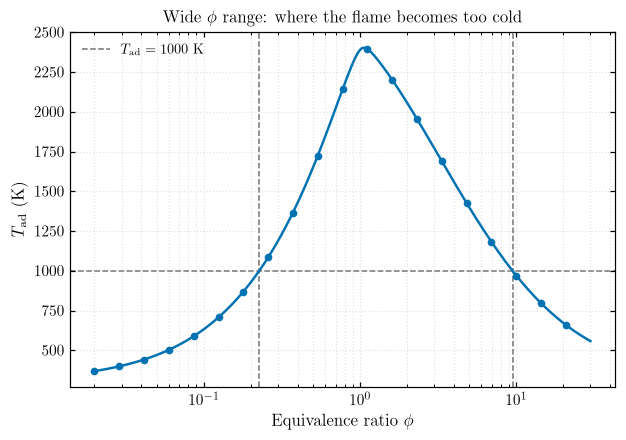

In [4]:
lean, rich = phi <= 0.9, phi >= 1.3
print(f"Peak            : T_ad = {T_ad[k_max]:.1f} K at phi = {phi[k_max]:.2f}")
print(f"Lean-side slope : {eq.linear_slope(phi[lean], T_ad[lean]):7.0f} K per unit phi  (0.4 <= phi <= 0.9)")
print(f"Rich-side slope : {eq.linear_slope(phi[rich], T_ad[rich]):7.0f} K per unit phi  (1.3 <= phi <= 3.0)")

phi_wide = np.geomspace(0.02, 30, 2000)
T_wide = eq.equilibrium_sweep(phi_wide)
phi_lean_1000, phi_rich_1000 = eq.crossings(phi_wide, T_wide, 1000.0)
print(f"T_ad < 1000 K   : phi < {phi_lean_1000:.2f} (lean)   and   phi > {phi_rich_1000:.1f} (rich)")

fig, ax = plots.plot(
    phi_wide, T_wide, r"Equivalence ratio $\phi$", r"$T_\mathrm{ad}$ (K)", xscale="log",
    hlines={1000.0: r"$T_\mathrm{ad} = 1000$ K"},
    vlines=[phi_lean_1000, phi_rich_1000], markevery=100, legend=True,
    title=r"Wide $\phi$ range: where the flame becomes too cold",
)
plots.save_figure(fig, "task1_Tad_vs_phi_wide")
plt.show()

### Answers

- **Peak:** $\approx 2403$ K at $\phi \approx 1.06$, not at $\phi = 1$. Slightly rich mixtures suppress dissociation (excess H$_2$ shifts $\mathrm{H_2O \rightleftharpoons H_2 + \tfrac{1}{2}O_2}$ back), and the excess H$_2$ adds little heat capacity.
- **Steeper lean side:** $+1760$ K vs $-330$ K per unit $\phi$. Lean, every bit of fuel removed is lost heat release; rich, heat release is capped by O$_2$ and the extra H$_2$ is only a light diluent.
- **Below 1000 K:** $\phi < 0.23$ and $\phi > 9.5$. Below roughly 1000 K a flame cannot sustain itself, so these points bracket the flammability limits (measured for H$_2$/air: about $\phi = 0.1$–$7$).

### Other preheat temperatures and pressures

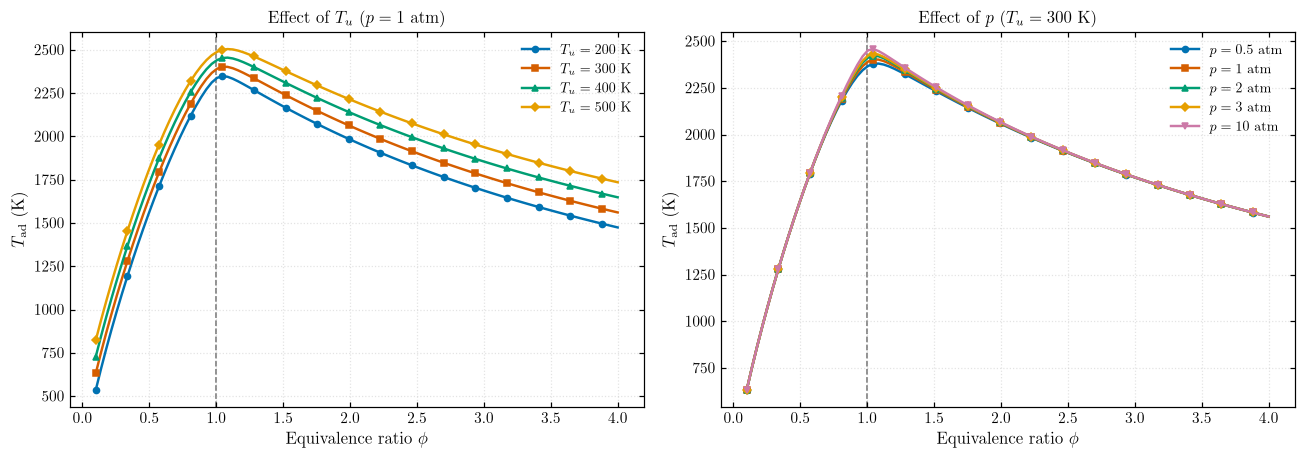

In [5]:
phi_ext = np.linspace(0.1, 4.0, 100)
T_u_list = [200, 300, 400, 500]                # K
p_list = [0.5, 1.0, 2.0, 3.0, 10.0]            # atm

T_by_Tu = [eq.equilibrium_sweep(phi_ext, T_u=T_u) for T_u in T_u_list]
T_by_p = [eq.equilibrium_sweep(phi_ext, p=p * ATM) for p in p_list]

eq.save_dataframe(pd.DataFrame({"phi": phi_ext, **{f"T_ad_Tu{T_u:.0f}K": T for T_u, T in zip(T_u_list, T_by_Tu)}}),
                  "task1_phi_sweep_vs_Tu")
eq.save_dataframe(pd.DataFrame({"phi": phi_ext, **{f"T_ad_p{p:g}atm": T for p, T in zip(p_list, T_by_p)}}),
                  "task1_phi_sweep_vs_p")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
plots.plot(phi_ext, T_by_Tu, r"Equivalence ratio $\phi$", r"$T_\mathrm{ad}$ (K)", ax=axes[0],
           labels=[rf"$T_u = {T_u}$ K" for T_u in T_u_list], markevery=6, vlines=1.0,
           title=r"Effect of $T_u$ ($p = 1$ atm)")
plots.plot(phi_ext, T_by_p, r"Equivalence ratio $\phi$", r"$T_\mathrm{ad}$ (K)", ax=axes[1],
           labels=[rf"$p = {p:g}$ atm" for p in p_list], markevery=6, vlines=1.0,
           title=r"Effect of $p$ ($T_u = 300$ K)")
fig.tight_layout()
plots.save_figure(fig, "task1_Tad_vs_phi_Tu_and_p")
plt.show()

# Task 2 — Preheat Temperature Sweep

$T_u$ from 300 to 800 K at 1 atm, for $\phi = 0.7$, 1.0, 1.3. **`eq.equilibrium_sweep_Tu(T_u_range, phi, ...)`** is the $T_u$ version of the sweep.

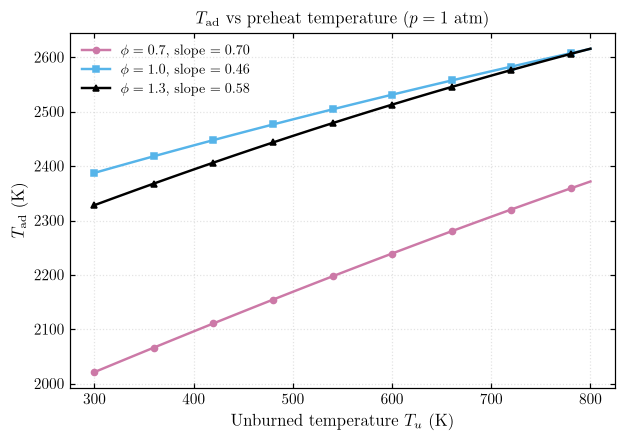

 phi  dTad/dTu (K/K)
 0.7           0.702
 1.0           0.455
 1.3           0.575


In [6]:
T_u = np.linspace(300, 800, 26)
phi_list = [0.7, 1.0, 1.3]

T_by_phi = [eq.equilibrium_sweep_Tu(T_u, phi=f) for f in phi_list]
slopes = [eq.linear_slope(T_u, T) for T in T_by_phi]

eq.save_dataframe(pd.DataFrame({"T_u": T_u, **{f"T_ad_phi{f}": T for f, T in zip(phi_list, T_by_phi)}}),
                  "task2_Tu_sweep")

fig, ax = plots.plot(
    T_u, T_by_phi, r"Unburned temperature $T_u$ (K)", r"$T_\mathrm{ad}$ (K)",
    labels=[rf"$\phi = {f}$, slope $= {s:.2f}$" for f, s in zip(phi_list, slopes)],
    colors=plots.PALETTE[4:7], markevery=3,
    title=r"$T_\mathrm{ad}$ vs preheat temperature ($p = 1$ atm)",
)
plots.save_figure(fig, "task2_Tad_vs_Tu")
plt.show()

print(pd.DataFrame({"phi": phi_list, "dTad/dTu (K/K)": np.round(slopes, 3)}).to_string(index=False))

**`eq.preheat_slope(phi_range, T_u_range, p)`** returns $\partial T_\mathrm{ad}/\partial T_u$ for each $\phi$.

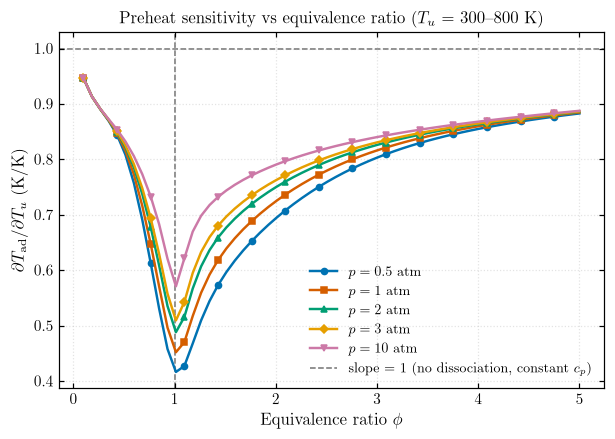

In [7]:
phi_s = np.linspace(0.1, 5.0, 60)
T_u_fit = np.linspace(300, 800, 11)
slope_by_p = [eq.preheat_slope(phi_s, T_u_fit, p=p * ATM) for p in p_list]

eq.save_dataframe(pd.DataFrame({"phi": phi_s, **{f"slope_p{p:g}atm": s for p, s in zip(p_list, slope_by_p)}}),
                  "task2_slope_vs_phi")

fig, ax = plots.plot(
    phi_s, slope_by_p, r"Equivalence ratio $\phi$", r"$\partial T_\mathrm{ad}/\partial T_u$ (K/K)",
    labels=[rf"$p = {p:g}$ atm" for p in p_list], markevery=4, vlines=1.0,
    hlines={1.0: "slope = 1 (no dissociation, constant $c_p$)"},
    title=r"Preheat sensitivity vs equivalence ratio ($T_u$ = 300--800 K)",
)
plots.save_figure(fig, "task2_slope_vs_phi")
plt.show()

### Gain from preheating 300 → 600 K

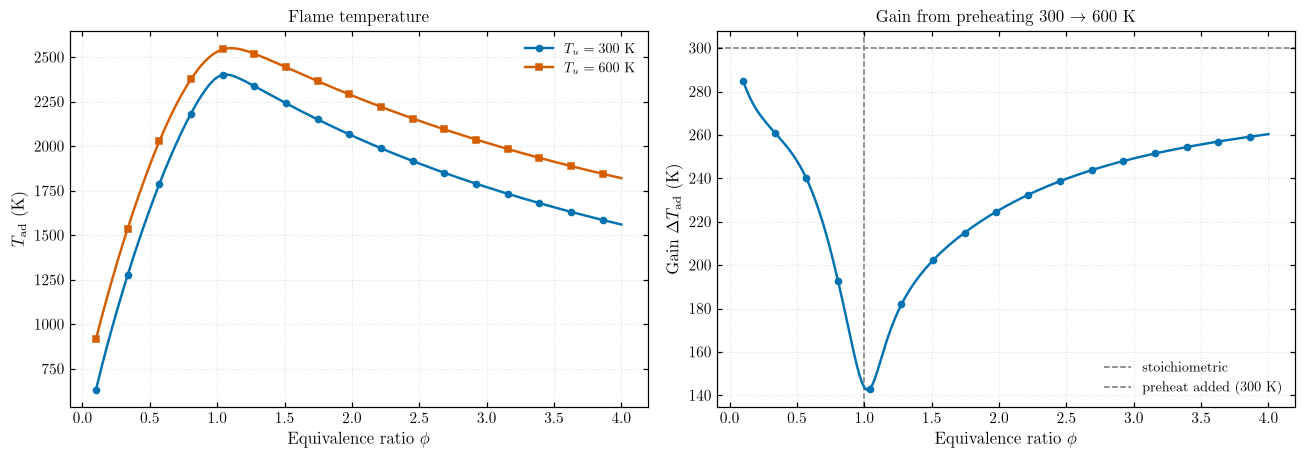

 phi  T_ad(300 K)  T_ad(600 K)  gain (K)
 0.3       1189.0       1453.0     264.0
 0.5       1646.0       1894.0     248.0
 0.7       2021.0       2239.0     218.0
 1.0       2388.0       2531.0     144.0
 1.3       2328.0       2513.0     185.0
 2.0       2060.0       2286.0     225.0
 3.0       1771.0       2020.0     249.0


In [8]:
phi_g = np.linspace(0.1, 4.0, 200)
T300 = eq.equilibrium_sweep(phi_g, T_u=300.0)
T600 = eq.equilibrium_sweep(phi_g, T_u=600.0)
gain = T600 - T300

eq.save_dataframe(pd.DataFrame({"phi": phi_g, "T_ad_300K": T300, "T_ad_600K": T600, "gain": gain}),
                  "task2_preheat_gain")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
plots.plot(phi_g, [T300, T600], r"Equivalence ratio $\phi$", r"$T_\mathrm{ad}$ (K)", ax=axes[0],
           labels=[r"$T_u = 300$ K", r"$T_u = 600$ K"], markevery=12, title="Flame temperature")
plots.plot(phi_g, gain, r"Equivalence ratio $\phi$", r"Gain $\Delta T_\mathrm{ad}$ (K)", ax=axes[1],
           markevery=12, vlines={1.0: "stoichiometric"}, hlines={300.0: "preheat added (300 K)"},
           title=r"Gain from preheating 300 $\to$ 600 K")
fig.tight_layout()
plots.save_figure(fig, "task2_preheat_gain")
plt.show()

table = pd.DataFrame({"phi": [0.3, 0.5, 0.7, 1.0, 1.3, 2.0, 3.0]})
table["T_ad(300 K)"] = np.interp(table.phi, phi_g, T300).round(0)
table["T_ad(600 K)"] = np.interp(table.phi, phi_g, T600).round(0)
table["gain (K)"] = np.interp(table.phi, phi_g, gain).round(0)
print(table.to_string(index=False))

### Overview in 2D and 3D

**`plots.surface_3d(x, y, Z, xlabel, ylabel, zlabel, lines=...)`** draws a surface, optionally with curves on it.

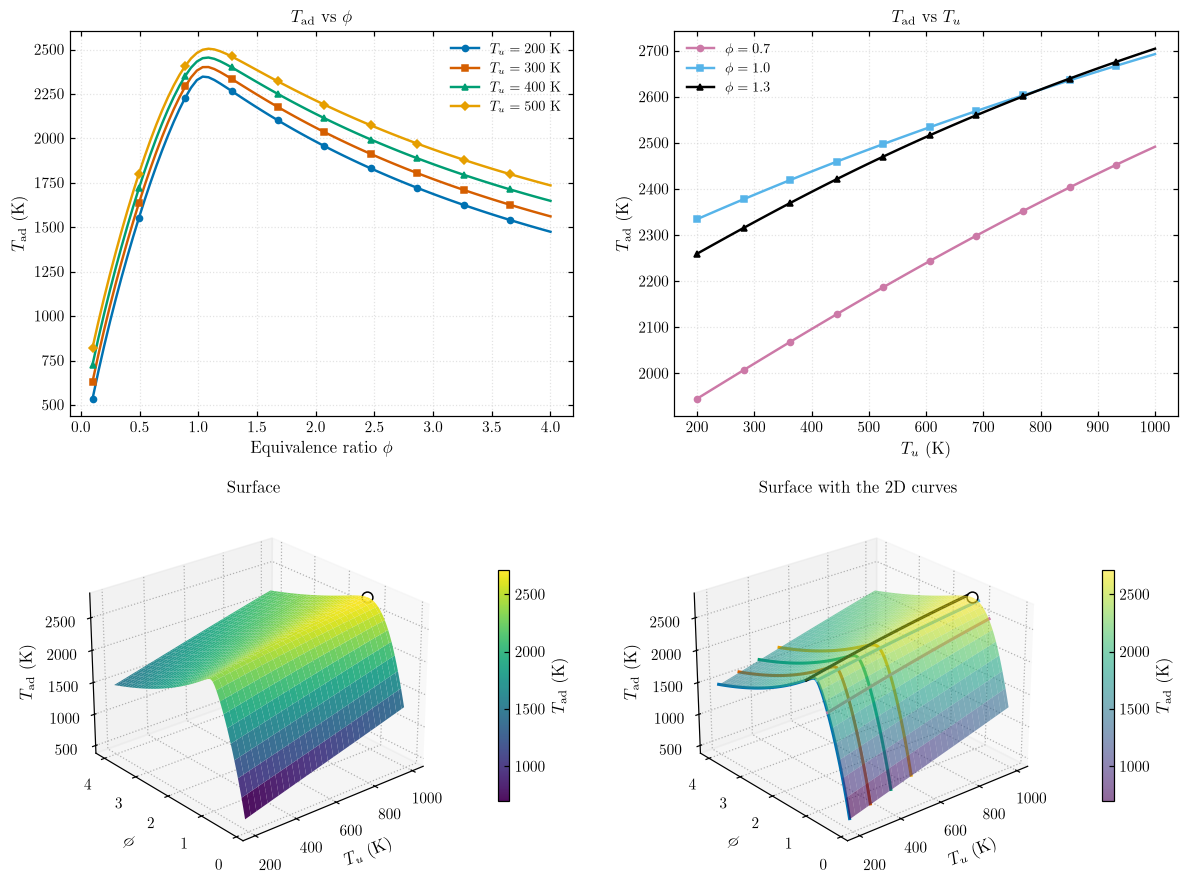

In [9]:
T_u_s = np.linspace(200, 1000, 60)
phi_s3 = np.linspace(0.1, 4.0, 80)
T_surf = eq.equilibrium_map(phi_s3, T_u_s, "T_u")          # shape (len(phi), len(T_u))

Tu_lines, phi_lines = [200, 300, 400, 500], [0.7, 1.0, 1.3]
col_Tu, col_phi = plots.PALETTE[:4], plots.PALETTE[4:7]
T_Tu_lines = [eq.equilibrium_sweep(phi_s3, T_u=T) for T in Tu_lines]
T_phi_lines = [eq.equilibrium_sweep_Tu(T_u_s, phi=f) for f in phi_lines]

fig = plt.figure(figsize=(13, 10))
ax1, ax2 = fig.add_subplot(2, 2, 1), fig.add_subplot(2, 2, 2)
ax3, ax4 = fig.add_subplot(2, 2, 3, projection="3d"), fig.add_subplot(2, 2, 4, projection="3d")

plots.plot(phi_s3, T_Tu_lines, r"Equivalence ratio $\phi$", r"$T_\mathrm{ad}$ (K)", ax=ax1,
           labels=[rf"$T_u = {T}$ K" for T in Tu_lines], colors=col_Tu, markevery=8,
           title=r"$T_\mathrm{ad}$ vs $\phi$")
plots.plot(T_u_s, T_phi_lines, r"$T_u$ (K)", r"$T_\mathrm{ad}$ (K)", ax=ax2,
           labels=[rf"$\phi = {f}$" for f in phi_lines], colors=col_phi, markevery=6,
           title=r"$T_\mathrm{ad}$ vs $T_u$")

lines = ([dict(x=phi_s3 * 0 + T, y=phi_s3, z=Tl, color=c) for T, Tl, c in zip(Tu_lines, T_Tu_lines, col_Tu)]
         + [dict(x=T_u_s, y=T_u_s * 0 + f, z=Tl, color=c) for f, Tl, c in zip(phi_lines, T_phi_lines, col_phi)])
labels3d = (r"$T_u$ (K)", r"$\phi$", r"$T_\mathrm{ad}$ (K)")
plots.surface_3d(T_u_s, phi_s3, T_surf, *labels3d, ax=ax3, title="Surface")
plots.surface_3d(T_u_s, phi_s3, T_surf, *labels3d, ax=ax4, lines=lines, title="Surface with the 2D curves")

plots.save_figure(fig, "task2_overview_2d_3d")
plt.show()

### Answers

- **Slope:** $\approx 0.70$, $0.46$, $0.58$ at $\phi = 0.7$, $1.0$, $1.3$; well below 1. The extra enthalpy goes partly into dissociation, and hot products have a higher $c_p$ than cold reactants.
- **Dependence on $\phi$:** yes. The slope is lowest at $\phi \approx 1$ (hottest flame, most dissociation) and approaches 1 for very lean or rich mixtures. Higher pressure raises it near $\phi = 1$.
- **Gain at 600 K:** $\approx 144$ K at $\phi = 1$, less than half of the 300 K added. It is larger away from stoichiometric: $\approx 218$ K at $\phi = 0.7$, $\approx 185$ K at $\phi = 1.3$. So lean and rich are not the same.

# Task 3 — Pressure Sweep and Equilibrium Composition

$\phi = 1$, $T_u = 300$ K, $p$ from 1 to 20 atm. **`eq.equilibrium_state(phi, ...)`** returns the equilibrated `cantera.Solution`, so any property can be read.

In [10]:
gas_st = eq.equilibrium_state(1.0)
top = sorted(gas_st.mole_fraction_dict().items(), key=lambda kv: -kv[1])
print(f"T_ad = {gas_st.T:.1f} K at 1 atm\n")
print(pd.DataFrame(top, columns=["species", "X"]).to_string(index=False, float_format="%.3e"))

T_ad = 2387.6 K at 1 atm

species         X
     N2 6.458e-01
    H2O 3.244e-01
     H2 1.457e-02
     OH 7.285e-03
     O2 5.609e-03
      H 1.811e-03
      O 6.074e-04
    HO2 1.257e-06
   H2O2 1.339e-07


**`eq.equilibrium_sweep_p`** sweeps pressure; **`eq.mole_fractions(states, species)`** extracts species; **`eq.power_law_exponent(x, y)`** fits $y \propto x^n$.

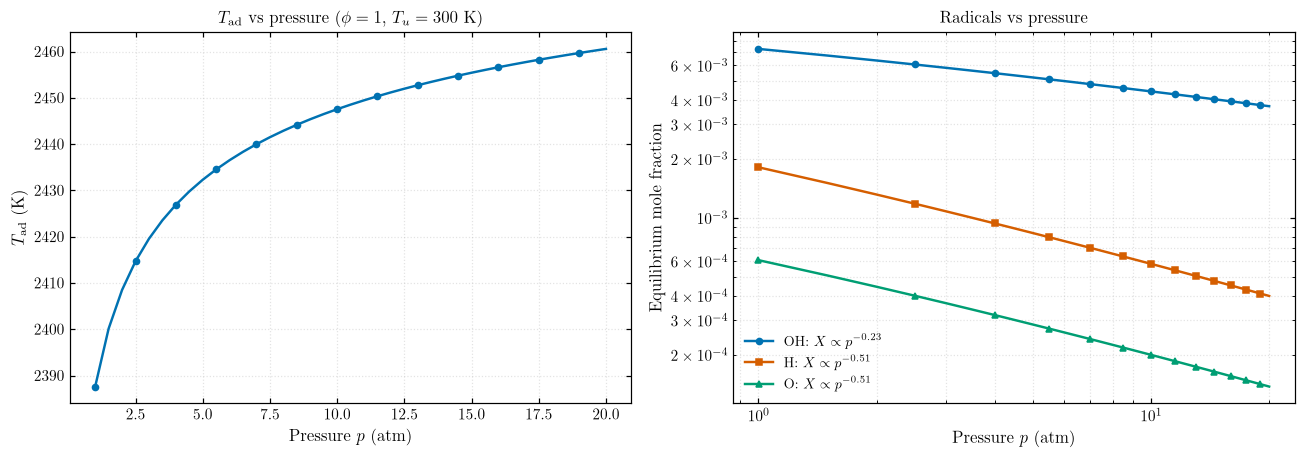

T_ad: 2387.6 K at 1 atm -> 2460.6 K at 20 atm  (+73.0 K, +3.1 %)
X_OH: 7.28e-03 -> 3.71e-03   (factor 2.0 lower, n = -0.23)
X_H : 1.81e-03 -> 3.99e-04   (factor 4.5 lower, n = -0.51)
X_O : 6.07e-04 -> 1.37e-04   (factor 4.4 lower, n = -0.51)


In [11]:
p = np.linspace(1, 20, 39) * ATM
states_p = eq.equilibrium_states(1.0, T_u=300.0, p=p)
eq.save_states(states_p, "task3_p_sweep")

species = ["OH", "H", "O"]
X = eq.mole_fractions(states_p, species)
n = {sp: eq.power_law_exponent(p, X[sp]) for sp in species}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
plots.plot(p / ATM, states_p.T, r"Pressure $p$ (atm)", r"$T_\mathrm{ad}$ (K)", ax=axes[0],
           markevery=3, legend=False, title=r"$T_\mathrm{ad}$ vs pressure ($\phi = 1$, $T_u = 300$ K)")
plots.plot(p / ATM, [X[sp] for sp in species], r"Pressure $p$ (atm)", "Equilibrium mole fraction",
           ax=axes[1], labels=[rf"{sp}: $X \propto p^{{{n[sp]:.2f}}}$" for sp in species],
           xscale="log", yscale="log", markevery=3, title="Radicals vs pressure")
fig.tight_layout()
plots.save_figure(fig, "task3_Tad_and_radicals_vs_p")
plt.show()

dT = states_p.T[-1] - states_p.T[0]
print(f"T_ad: {states_p.T[0]:.1f} K at 1 atm -> {states_p.T[-1]:.1f} K at 20 atm  (+{dT:.1f} K, +{100 * dT / states_p.T[0]:.1f} %)")
for sp in species:
    print(f"X_{sp:<2}: {X[sp][0]:.2e} -> {X[sp][-1]:.2e}   (factor {X[sp][0] / X[sp][-1]:.1f} lower, n = {n[sp]:.2f})")

### Several equivalence ratios

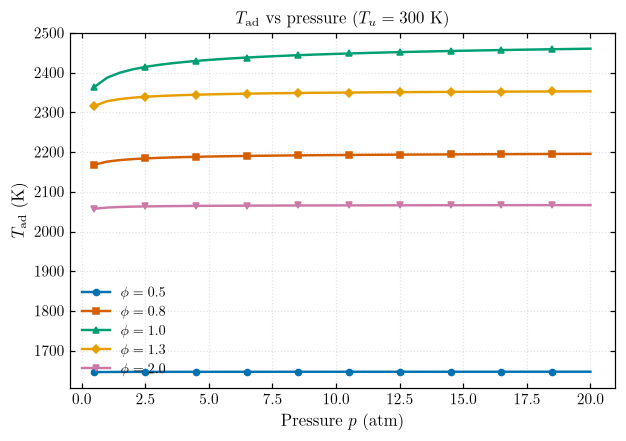

phi = 0.5:  T_ad rises by   1.0 K from 0.5 to 20 atm
phi = 0.8:  T_ad rises by  27.4 K from 0.5 to 20 atm
phi = 1.0:  T_ad rises by  96.3 K from 0.5 to 20 atm
phi = 1.3:  T_ad rises by  36.4 K from 0.5 to 20 atm
phi = 2.0:  T_ad rises by   9.3 K from 0.5 to 20 atm


In [12]:
P_atm = np.linspace(0.5, 20.0, 40)
phi_list_p = [0.5, 0.8, 1.0, 1.3, 2.0]
T_by_phi_p = [eq.equilibrium_sweep_p(P_atm * ATM, phi=f) for f in phi_list_p]

eq.save_dataframe(pd.DataFrame({"p_atm": P_atm, **{f"T_ad_phi{f}": T for f, T in zip(phi_list_p, T_by_phi_p)}}),
                  "task3_Tad_vs_p_phis")

fig, ax = plots.plot(P_atm, T_by_phi_p, r"Pressure $p$ (atm)", r"$T_\mathrm{ad}$ (K)",
                     labels=[rf"$\phi = {f}$" for f in phi_list_p], markevery=4,
                     title=r"$T_\mathrm{ad}$ vs pressure ($T_u = 300$ K)")
plots.save_figure(fig, "task3_Tad_vs_p_phis")
plt.show()

for f, T in zip(phi_list_p, T_by_phi_p):
    print(f"phi = {f:3.1f}:  T_ad rises by {T[-1] - T[0]:5.1f} K from 0.5 to 20 atm")

### Radical maps

**`plots.contour_map(x, y, Z, xlabel, ylabel, zlabel, isolines=...)`** draws a filled contour map with a colour bar.

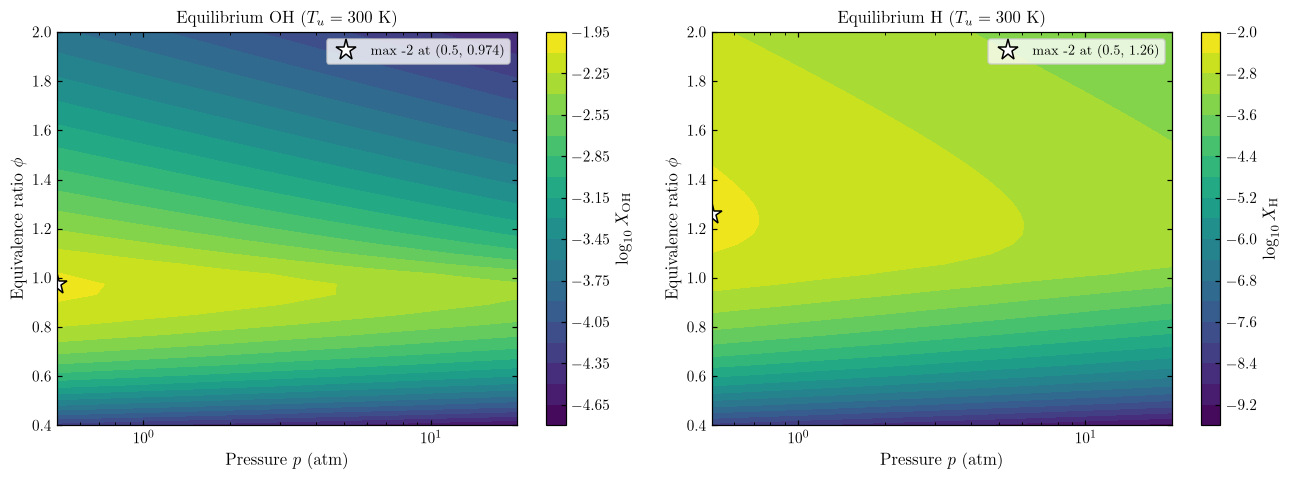

In [13]:
P_map = np.geomspace(0.5, 20, 40) * ATM
phi_map = np.linspace(0.4, 2.0, 40)
PHI, PP = np.meshgrid(phi_map, P_map, indexing="ij")
states_rad = eq.equilibrium_states(PHI, T_u=300.0, p=PP)
eq.save_states(states_rad, "task3_radical_map")
X_map = {sp: v.reshape(PHI.shape) for sp, v in eq.mole_fractions(states_rad, ["OH", "H"]).items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, sp in zip(axes, ["OH", "H"]):
    plots.contour_map(P_map / ATM, phi_map, np.log10(X_map[sp]), r"Pressure $p$ (atm)",
                      r"Equivalence ratio $\phi$", rf"$\log_{{10}} X_\mathrm{{{sp}}}$",
                      ax=ax, xscale="log", title=rf"Equilibrium {sp} ($T_u = 300$ K)")
fig.tight_layout()
plots.save_figure(fig, "task3_radical_maps")
plt.show()

### Le Chatelier's principle

OH, H and O come from dissociation reactions that increase the number of gas moles, e.g. $\mathrm{H_2 \rightleftharpoons 2H}$, $\mathrm{H_2O \rightleftharpoons H + OH}$. Higher pressure shifts them back toward fewer moles:

$$
K_p(T) = \prod_i X_i^{\nu_i}\left(\frac{p}{p^\circ}\right)^{\Delta\nu}
\quad\Rightarrow\quad X_\mathrm{H} \propto p^{-1/2} \text{ for } \mathrm{H_2 \rightleftharpoons 2H}
$$

| Symbol | Meaning | SI unit |
|---|---|---|
| $K_p$ | Equilibrium constant | – |
| $X_i$, $\nu_i$ | Mole fraction, stoichiometric coefficient | – |
| $\Delta\nu$ | Change in gas moles | – |
| $p$, $p^\circ$ | Pressure, standard pressure | Pa |

### Thermal NO$_x$

Thermal NO is driven by O atoms (Zeldovich): $\dfrac{\mathrm{d[NO]}}{\mathrm{d}t} \approx 2k_1[\mathrm{O}][\mathrm{N_2}]$, $k_1 = 1.8\times10^{11}\, e^{-38370/T}$.

| Symbol | Meaning | SI unit |
|---|---|---|
| $[\cdot]$ | Molar concentration | kmol/m³ |
| $k_1$ | Rate constant of $\mathrm{O + N_2 \rightarrow NO + N}$ | m³/(kmol·s) |
| $T$ | Temperature | K |

**`eq.zeldovich_no_rate(states)`** evaluates this in ppm/ms. Gas-turbine conditions: $T_u = 700$ K, 1–30 atm; shaded band = lean-premixed window.

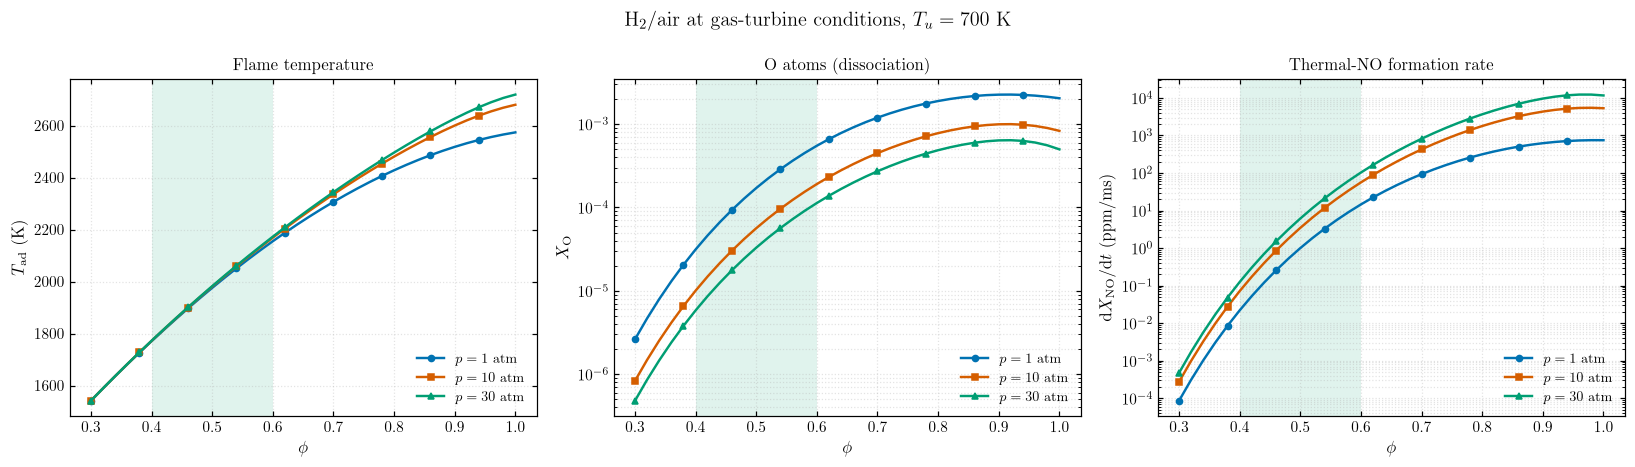

 p (atm)  dNO/dt at phi=0.5 (ppm/ms)  dNO/dt at phi=1.0 (ppm/ms)
       1                       0.999                         747
      10                        3.45                    5.31e+03
      30                        6.14                    1.16e+04


In [14]:
phi_nox = np.linspace(0.3, 1.0, 36)
p_nox = [1, 10, 30]                     # atm
T_u_nox = 700.0                         # K

states_nox = [eq.equilibrium_states(phi_nox, T_u=T_u_nox, p=pa * ATM) for pa in p_nox]
for pa, st in zip(p_nox, states_nox):
    eq.save_states(st, f"task3_nox_{pa}atm")

T_nox = [st.T for st in states_nox]
XO_nox = [eq.mole_fractions(st, ["O"])["O"] for st in states_nox]
dNO = [eq.zeldovich_no_rate(st) for st in states_nox]

labels = [rf"$p = {pa}$ atm" for pa in p_nox]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
plots.plot(phi_nox, T_nox, r"$\phi$", r"$T_\mathrm{ad}$ (K)", ax=axes[0], labels=labels,
           markevery=4, title="Flame temperature")
plots.plot(phi_nox, XO_nox, r"$\phi$", r"$X_\mathrm{O}$", ax=axes[1], labels=labels,
           yscale="log", markevery=4, title="O atoms (dissociation)")
plots.plot(phi_nox, dNO, r"$\phi$", r"$\mathrm{d}X_\mathrm{NO}/\mathrm{d}t$ (ppm/ms)", ax=axes[2],
           labels=labels, yscale="log", markevery=4, title="Thermal-NO formation rate")
for ax in axes:
    ax.axvspan(0.4, 0.6, color=plots.PALETTE[2], alpha=0.12, lw=0)
fig.suptitle(rf"H$_2$/air at gas-turbine conditions, $T_u = {T_u_nox:.0f}$ K")
fig.tight_layout()
plots.save_figure(fig, "task3_thermal_no")
plt.show()

i05 = np.argmin(abs(phi_nox - 0.5))
print(pd.DataFrame({"p (atm)": p_nox,
                    "dNO/dt at phi=0.5 (ppm/ms)": [d[i05] for d in dNO],
                    "dNO/dt at phi=1.0 (ppm/ms)": [d[-1] for d in dNO]}).to_string(index=False, float_format="%.3g"))

### Answers

- **$T_\mathrm{ad}$ change:** only $+73$ K (3 %) from 1 to 20 atm. Without dissociation it would not change at all; the rise is largest near $\phi = 1$ and negligible at $\phi = 0.5$.
- **OH and H:** they fall with pressure ($X_\mathrm{H}, X_\mathrm{O} \propto p^{-0.51}$, $X_\mathrm{OH} \propto p^{-0.23}$) because their dissociation reactions have $\Delta\nu > 0$. OH is less sensitive because some of its formation routes have $\Delta\nu = 0$.
- **NO$_x$:** pressure lowers $X_\mathrm{O}$ but raises $[\mathrm{N_2}]$ and $T$, so the NO rate still increases with $p$, and turbines run at 20–40 atm. Temperature is the main lever: going from $\phi = 1$ to $\phi \approx 0.5$ cuts the rate by about three orders of magnitude, which is why gas turbines burn lean-premixed.

# Task 4 — 2D Equilibrium Maps

Map 1: $T_\mathrm{ad}(\phi, T_u)$, $\phi \in [0.5, 2]$, $T_u \in [300, 800]$ K, 1 atm, with the 1800 K isoline. Map 2: $T_\mathrm{ad}(\phi, p)$, $p \in [1, 20]$ atm, 300 K.

**`eq.equilibrium_map(phi_range, sweep_range, sweep_param="T_u" or "p", fixed_T_u, fixed_p)`** returns $T_\mathrm{ad}$ with shape `(len(phi_range), len(sweep_range))`.

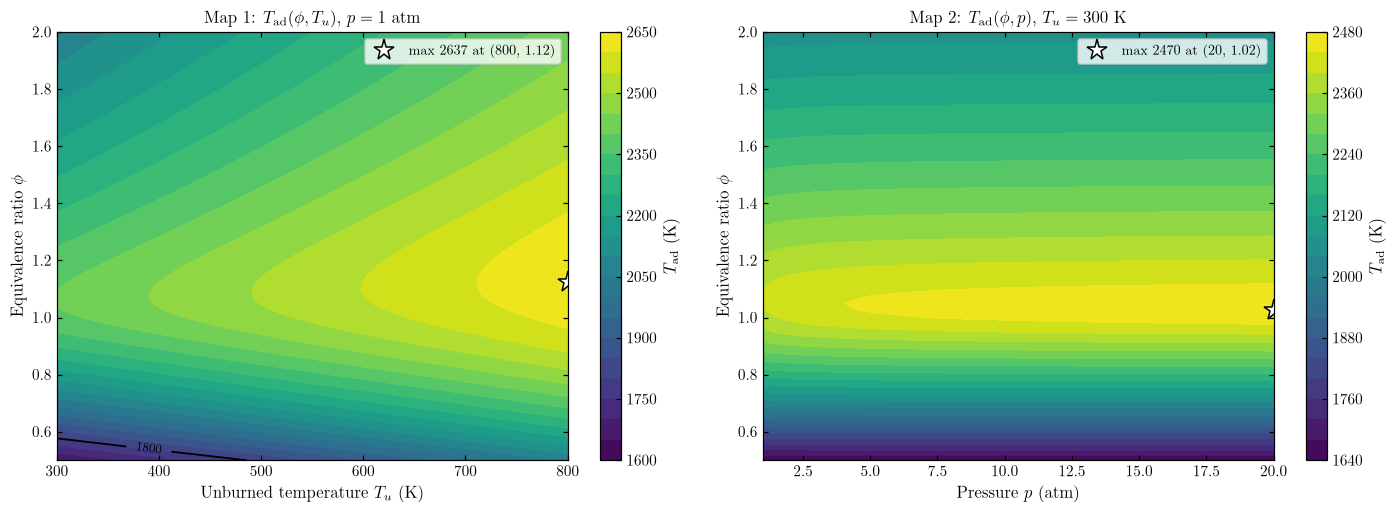

Map 1: max T_ad = 2637 K at phi = 1.125, 800 K
Map 2: max T_ad = 2470 K at phi = 1.025, 20 atm

At phi = 1: T_u 300 -> 800 K raises T_ad by 228 K; p 1 -> 20 atm raises it by 73 K
1800 K isoline: phi at T_u = 300 K: [0.577] | leaves the map (phi = 0.5) at T_u = [486.] K


In [15]:
phi_m = np.linspace(0.5, 2.0, 61)
T_u_m = np.linspace(300, 800, 51)
p_m = np.linspace(1, 20, 39) * ATM

map_Tu, states_m1 = eq.equilibrium_map(phi_m, T_u_m, "T_u", fixed_p=ATM, return_states=True)
map_p, states_m2 = eq.equilibrium_map(phi_m, p_m, "p", fixed_T_u=300.0, return_states=True)
eq.save_states(states_m1, "task4_map_phi_Tu")
eq.save_states(states_m2, "task4_map_phi_p")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plots.contour_map(T_u_m, phi_m, map_Tu, r"Unburned temperature $T_u$ (K)", r"Equivalence ratio $\phi$",
                  r"$T_\mathrm{ad}$ (K)", isolines=[1800], ax=axes[0],
                  title=r"Map 1: $T_\mathrm{ad}(\phi, T_u)$, $p = 1$ atm")
plots.contour_map(p_m / ATM, phi_m, map_p, r"Pressure $p$ (atm)", r"Equivalence ratio $\phi$",
                  r"$T_\mathrm{ad}$ (K)", ax=axes[1],
                  title=r"Map 2: $T_\mathrm{ad}(\phi, p)$, $T_u = 300$ K")
fig.tight_layout()
plots.save_figure(fig, "task4_maps")
plt.show()

for name, M, axis, unit in [("Map 1", map_Tu, T_u_m, "K"), ("Map 2", map_p, p_m / ATM, "atm")]:
    i, j = np.unravel_index(np.argmax(M), M.shape)
    print(f"{name}: max T_ad = {M[i, j]:.0f} K at phi = {phi_m[i]:.3f}, {axis[j]:.0f} {unit}")

i1 = np.argmin(abs(phi_m - 1.0))
print(f"\nAt phi = 1: T_u 300 -> 800 K raises T_ad by {map_Tu[i1, -1] - map_Tu[i1, 0]:.0f} K; "
      f"p 1 -> 20 atm raises it by {map_p[i1, -1] - map_p[i1, 0]:.0f} K")
print("1800 K isoline: phi at T_u = 300 K:", np.round(eq.crossings(phi_m, map_Tu[:, 0], 1800.0), 3),
      "| leaves the map (phi = 0.5) at T_u =", np.round(eq.crossings(T_u_m, map_Tu[0], 1800.0), 0), "K")

### As surfaces

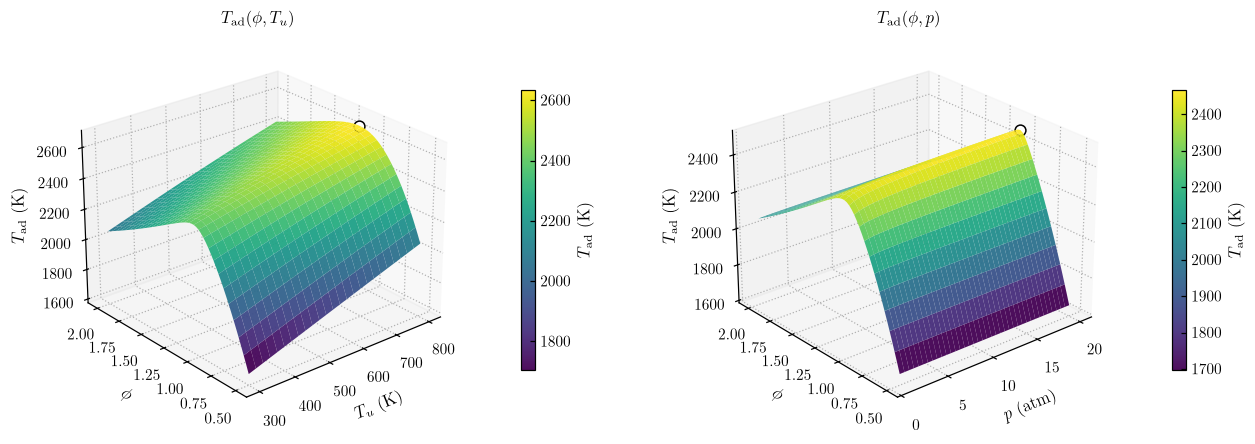

In [16]:
fig = plt.figure(figsize=(14, 5.5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
plots.surface_3d(T_u_m, phi_m, map_Tu, r"$T_u$ (K)", r"$\phi$", r"$T_\mathrm{ad}$ (K)", ax=ax1,
                 title=r"$T_\mathrm{ad}(\phi, T_u)$")
plots.surface_3d(p_m / ATM, phi_m, map_p, r"$p$ (atm)", r"$\phi$", r"$T_\mathrm{ad}$ (K)", ax=ax2,
                 title=r"$T_\mathrm{ad}(\phi, p)$")
plots.save_figure(fig, "task4_surfaces")
plt.show()

### Answers

- **Hottest point:** Map 1, $\approx 2637$ K at $T_u = 800$ K, $\phi \approx 1.13$. Map 2, $\approx 2470$ K at 20 atm, $\phi \approx 1.03$. Both are at the highest $T_u$ or $p$, and slightly rich.
- **1800 K isoline:** the boundary between mixtures hotter and colder than 1800 K, roughly where thermal NO$_x$ becomes significant. It lies on the lean side ($\phi \approx 0.58$ at 300 K) and leaves the map at $T_u \approx 486$ K. It marks the low-NO$_x$ operating limit, and shows that more preheat forces a leaner mixture, closer to blow-off.
- **Stronger driver:** $T_u$. At $\phi = 1$, 300 → 800 K adds $\approx 228$ K, while 1 → 20 atm adds only $\approx 73$ K.

# Summary

| Quantity | Value |
|---|---|
| $T_\mathrm{ad}$ at $\phi = 1$, 300 K, 1 atm | 2388 K |
| Peak | 2403 K at $\phi \approx 1.06$ |
| $T_\mathrm{ad} < 1000$ K | $\phi < 0.23$ or $\phi > 9.5$ |
| $\partial T_\mathrm{ad}/\partial T_u$ ($\phi = 0.7, 1.0, 1.3$) | 0.70, 0.46, 0.58 |
| Gain 300 → 600 K, $\phi = 1$ | +144 K |
| Change 1 → 20 atm, $\phi = 1$ | +73 K |
| Hottest point, Map 1 / Map 2 | 2637 K / 2470 K |